In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from skimage import data             # Contiene un conjunto de imágenes (ejemplo: data.camera() – Imagen en escala de grises de una cámara.)
from skimage.color import rgb2gray   # Convierte una imagen RGB (color) en una imagen en escala de grises.
from skimage.transform import resize # Redimensiona una imagen a un nuevo tamaño (alto × ancho).

Se Toma una imagen de la Data (chelsea: una gata) y se procesa para convertirla a TensorFlow/Keras.

TensorFlow/Keras espera que las imágenes tengan 4 dimensiones:
* Dimensión 0: batch size (número de imágenes en el lote)
* Dimensión 1: altura de la imagen
* Dimensión 2: ancho de la imagen
* Dimensión 3: canales de color (1 para escala de grises, 3 para RGB)



In [2]:
# --- 1. Cargar y Preprocesar la Imagen ---

print("Cargando y preparando la imagen...")
imagen_color = data.chelsea()                                         # imagen en color (RGB) de un gato doméstico. Dimensiones: (300, 451, 3)
imagen_gris = rgb2gray(imagen_color)
imagen_original = resize(imagen_gris, (256, 256))
imagen_para_tf = np.expand_dims(imagen_original, axis=[0, -1])        # convierte la imagen en un batch con una sola imagen (0) e imagen en escala de grises (-1)

print(f"Forma original de la imagen: {imagen_original.shape}")
print(f"Forma de la imagen para TensorFlow: {imagen_para_tf.shape}")  # resultado:(1, 256, 256, 1): Número de imágenes, Altura, ancho, Número de canales (1 = gris)


Cargando y preparando la imagen...
Forma original de la imagen: (256, 256)
Forma de la imagen para TensorFlow: (1, 256, 256, 1)


CONSTRUCCION DEL MODELO

* Se define la capa `entrada`. Con `shape` se define la forma del tensor de entrada, sin incluir el tamaño del batch. (256, 256, 1) significa que cada entrada individual (por ejemplo, cada imagen) tiene: 256 píxeles de alto, 256 píxeles de ancho, 1 canal: lo cual indica que es una imagen en escala de grises.

* Se define la capa `capa_convolucional`. Esta capa toma una imagen, aplica 4 filtros de 7×7, aplica ReLU a los resultados, y produce 4 mapas de características que representan diferentes aspectos detectados en la imagen original.

* Se define la capa `capa_de_pooling`. Esta capa hace una reducción de dimensiones. Define una ventana de 2×2 píxeles que se desliza sobre los mapas de características (`pool_size=(2, 2)`). La ventana se mueve 2 píxeles hacia la derecha y 2 píxeles hacia abajo en cada paso (`strides=(2, 2)`).

In [3]:
# --- 2. Construir el Modelo con la API Funcional ---

# Definir la entrada explícitamente.
# Con shape se define la forma del tensor de entrada, sin incluir el tamaño del batch(altura, ancho, Número de canales:1 = gris)
input_layer = tf.keras.Input(shape=(256, 256, 1), name='entrada')

# Conectamos la capa convolucional a la entrada
conv_layer = tf.keras.layers.Conv2D(
    filters=4,
    kernel_size=(7, 7),
    activation='relu',
    name='capa_convolucional'
)(input_layer) # <- Se conecta aquí

# Conectamos la capa de pooling a la salida de la capa convolucional
pooling_layer = tf.keras.layers.MaxPooling2D(
    pool_size=(2, 2),
    strides=(2, 2),
    name='capa_de_pooling'
)(conv_layer) # <- Se conecta aquí

# Creamos el modelo final especificando las entradas y salidas
modelo = tf.keras.Model(inputs=input_layer, outputs=pooling_layer)

# Mostramos la arquitectura del modelo
print("\n--- Arquitectura del Modelo (API Funcional) ---")
modelo.summary()


--- Arquitectura del Modelo (API Funcional) ---


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ entrada (InputLayer)            │ (None, 256, 256, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa_convolucional (Conv2D)     │ (None, 250, 250, 4)    │           200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa_de_pooling (MaxPooling2D)  │ (None, 125, 125, 4)    │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 200 (800.00 B)

 Trainable params: 200 (800.00 B)

 Non-trainable params: 0 (0.00 B)

**Cálculo de parámetros:**

1. Pesos del kernel:

  * Cada filtro tiene tamaño (7, 7)
  * La entrada tiene 1 canal (escala de grises)
  * Hay 4 filtros
    * Pesos por filtro = 7 × 7 × 1 = 49
    * Total de pesos = 49 × 4 = 196

2. Bias (sesgo):

  * Cada filtro tiene 1 bias
    * Total de bias = 4 × 1 = 4

3. Total de parámetros:

  * Parámetros totales = Pesos + Bias
  * Parámetros totales = 196 + 4 = 200

In [4]:
# --- 3. Extraer las Salidas de cada Capa ---

# Obtener las salidas
salida_conv = modelo.get_layer('capa_convolucional').output
salida_pool = modelo.get_layer('capa_de_pooling').output

# Creamos el modelo de activación
# La entrada es la misma que la del modelo principal
# Las salidas son las capas que queremos inspeccionar
modelo_activacion = tf.keras.Model(inputs=modelo.input, outputs=[salida_conv, salida_pool])

# Pasar la imagen por este modelo para obtener las activaciones
activaciones = modelo_activacion.predict(imagen_para_tf)

# Obtenemos el resultado de cada capa
salida_conv_activacion = activaciones[0]
salida_pool_activacion = activaciones[1]

print(f"\nForma de la salida de Conv2D: {salida_conv_activacion.shape}")
print(f"Forma de la salida de MaxPooling2D: {salida_pool_activacion.shape}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 320ms/step

Forma de la salida de Conv2D: (1, 250, 250, 4)
Forma de la salida de MaxPooling2D: (1, 125, 125, 4)



Generando visualización original...


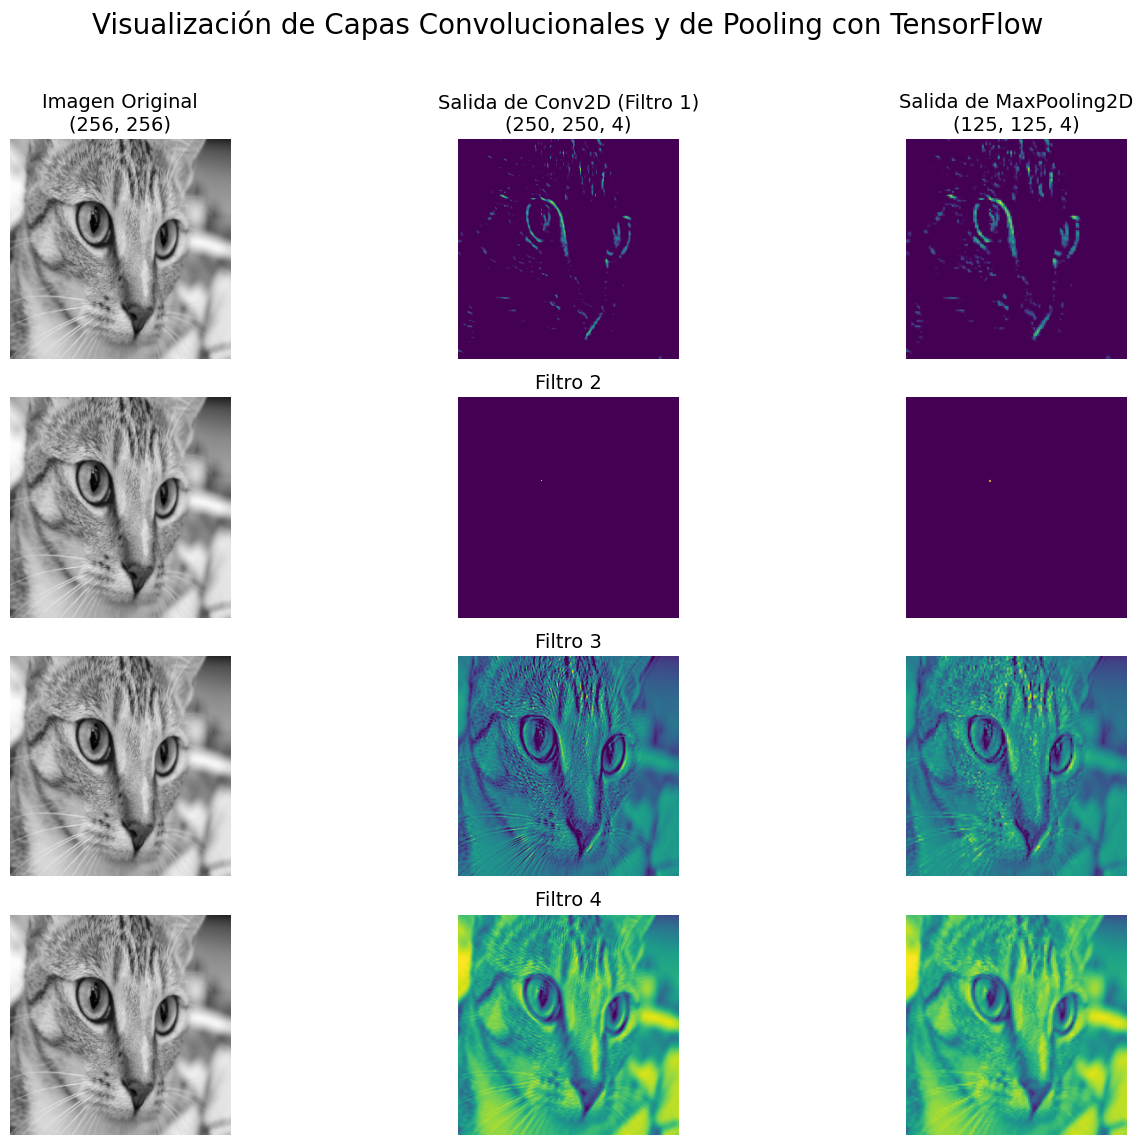

In [5]:
# --- 4. Visualizar los Resultados ---

print("\nGenerando visualización original...")
num_filtros = salida_conv_activacion.shape[-1]
fig, axes = plt.subplots(num_filtros, 3, figsize=(15, 12))

fig.suptitle("Visualización de Capas Convolucionales y de Pooling con TensorFlow", fontsize=20, y=0.95)

for i in range(num_filtros):
    ax = axes[i, 0]
    ax.imshow(imagen_original, cmap='gray')
    if i == 0:
      ax.set_title(f'Imagen Original\n{imagen_original.shape}', fontsize=14)
    ax.axis('off')

    ax = axes[i, 1]
    ax.imshow(salida_conv_activacion[0, :, :, i], cmap='viridis')
    if i == 0:
        ax.set_title(f'Salida de Conv2D (Filtro {i+1})\n{salida_conv_activacion.shape[1:]}', fontsize=14)
    else:
        ax.set_title(f'Filtro {i+1}', fontsize=14)
    ax.axis('off')

    ax = axes[i, 2]
    ax.imshow(salida_pool_activacion[0, :, :, i], cmap='viridis')
    if i == 0:
        ax.set_title(f'Salida de MaxPooling2D\n{salida_pool_activacion.shape[1:]}', fontsize=14)
    ax.axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()


--- Visualización Comparativa de Pooling ---


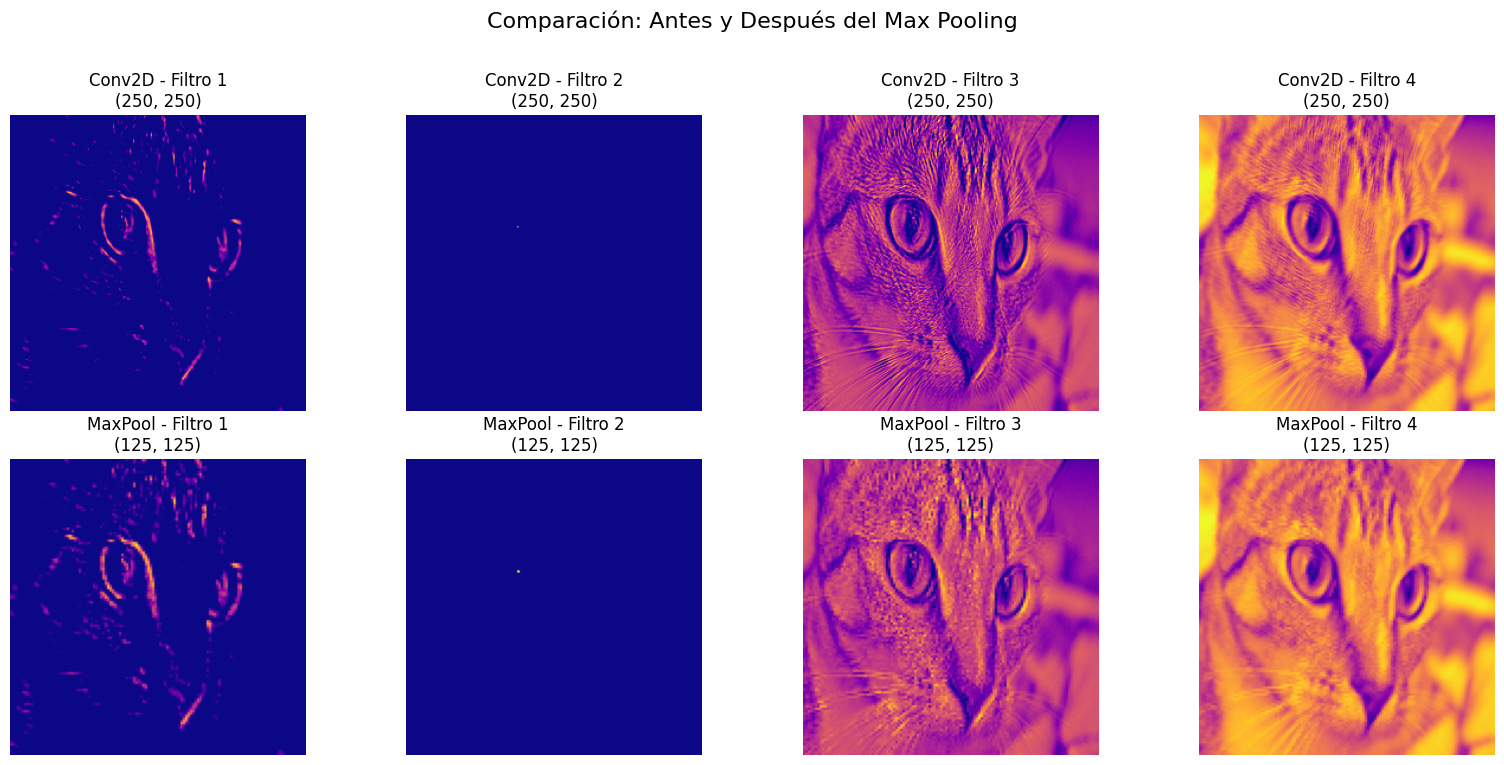

In [6]:
# --- 5. VISUALIZACIONES DE POOLING ---

# Visualización 1: Comparación lado a lado para cada filtro
print("\n--- Visualización Comparativa de Pooling ---")
fig, axes = plt.subplots(2, num_filtros, figsize=(16, 8))
fig.suptitle("Comparación: Antes y Después del Max Pooling", fontsize=16, y=0.95)

for i in range(num_filtros):
    # Antes del pooling
    axes[0, i].imshow(salida_conv_activacion[0, :, :, i], cmap='plasma')
    axes[0, i].set_title(f'Conv2D - Filtro {i+1}\n{salida_conv_activacion.shape[1:3]}', fontsize=12)
    axes[0, i].axis('off')

    # Después del pooling
    axes[1, i].imshow(salida_pool_activacion[0, :, :, i], cmap='plasma')
    axes[1, i].set_title(f'MaxPool - Filtro {i+1}\n{salida_pool_activacion.shape[1:3]}', fontsize=12)
    axes[1, i].axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()


--- Análisis de Reducción de Dimensionalidad ---


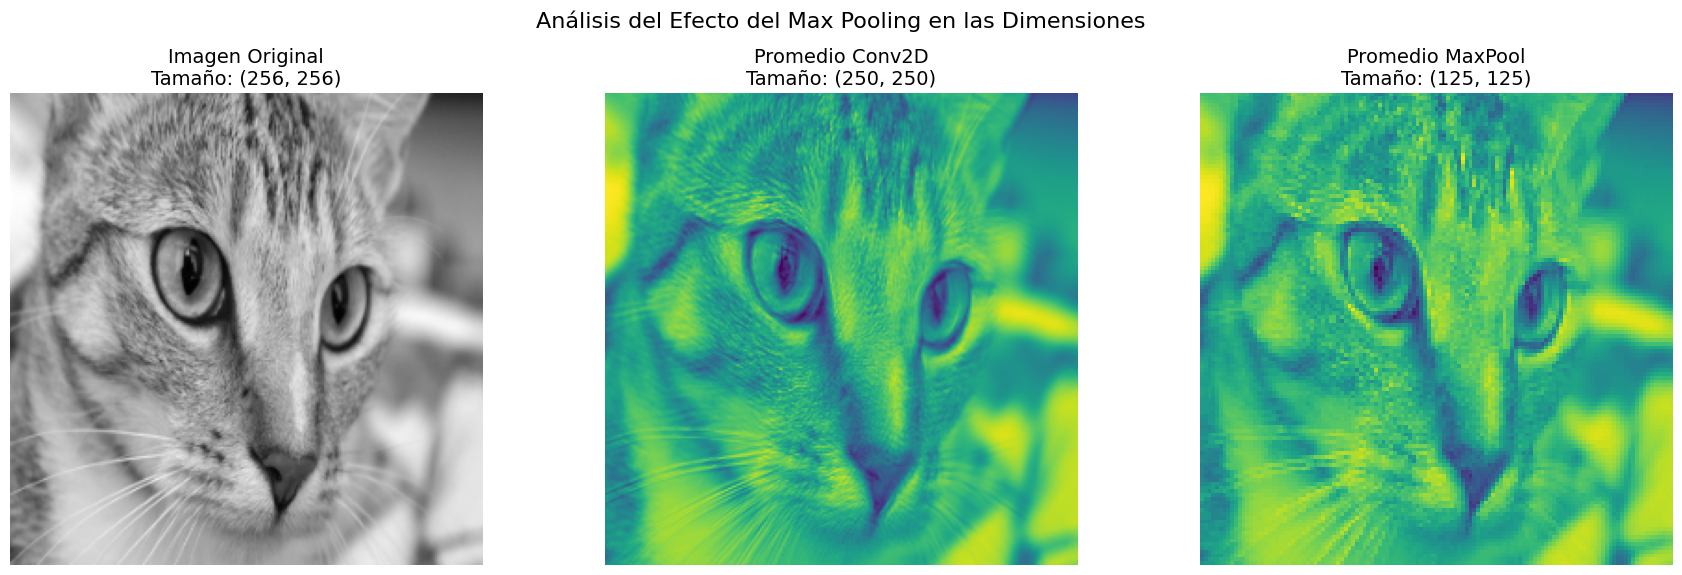

In [7]:
# Visualización 2: Análisis de reducción de dimensionalidad
print("\n--- Análisis de Reducción de Dimensionalidad ---")
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("Análisis del Efecto del Max Pooling en las Dimensiones", fontsize=16, y=0.95)

# Imagen original
axes[0].imshow(imagen_original, cmap='gray')
axes[0].set_title(f'Imagen Original\nTamaño: {imagen_original.shape}', fontsize=14)
axes[0].axis('off')

# Promedio de todas las activaciones de conv
conv_promedio = np.mean(salida_conv_activacion[0], axis=-1)
axes[1].imshow(conv_promedio, cmap='viridis')
axes[1].set_title(f'Promedio Conv2D\nTamaño: {conv_promedio.shape}', fontsize=14)
axes[1].axis('off')

# Promedio de todas las activaciones de pooling
pool_promedio = np.mean(salida_pool_activacion[0], axis=-1)
axes[2].imshow(pool_promedio, cmap='viridis')
axes[2].set_title(f'Promedio MaxPool\nTamaño: {pool_promedio.shape}', fontsize=14)
axes[2].axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()


--- Mapas de Calor con Estadísticas ---


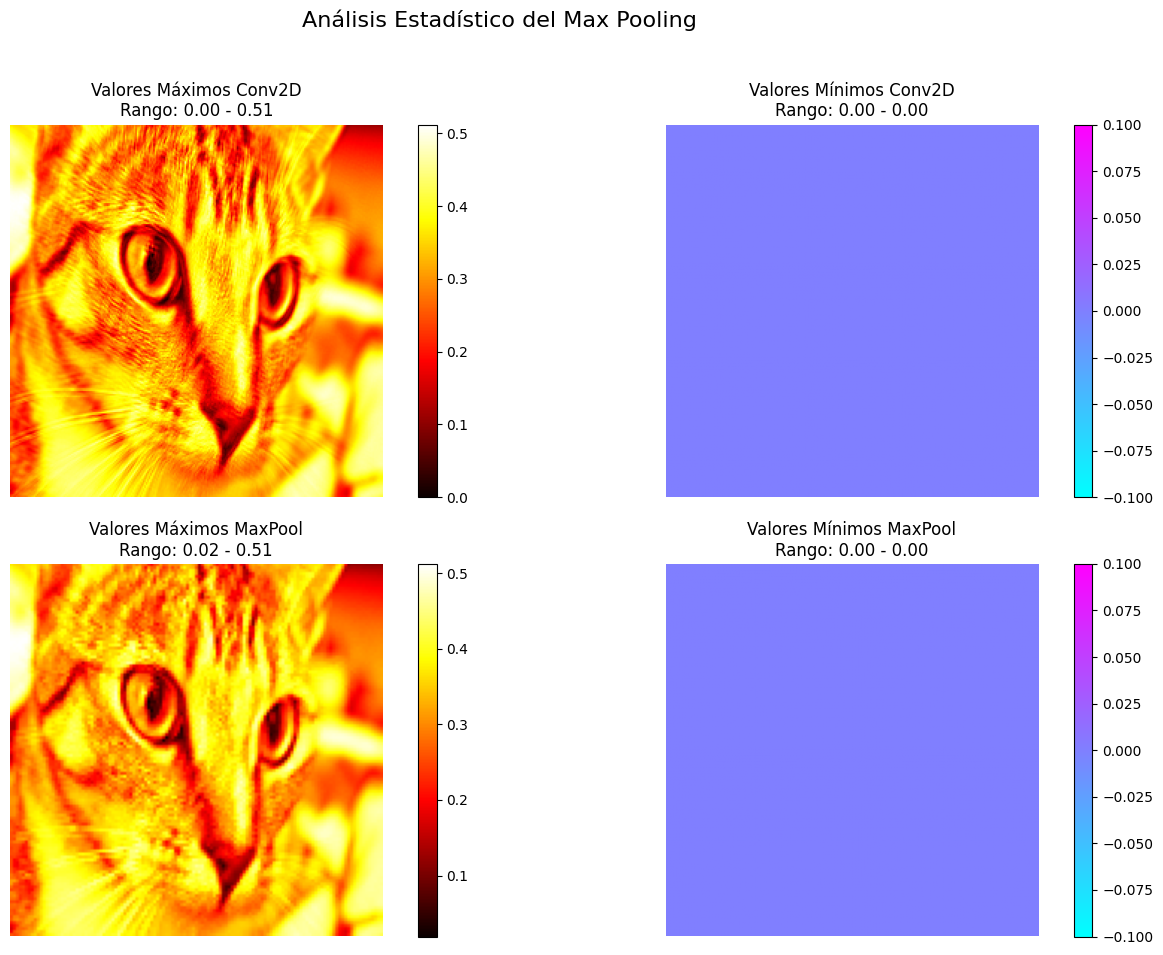

In [8]:
# Visualización 3: Mapas de calor con información estadística
print("\n--- Mapas de Calor con Estadísticas ---")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Análisis Estadístico del Max Pooling", fontsize=16, y=0.95)

# Estadísticas para Conv2D
conv_max = np.max(salida_conv_activacion[0], axis=-1)
conv_min = np.min(salida_conv_activacion[0], axis=-1)

# Estadísticas para MaxPool
pool_max = np.max(salida_pool_activacion[0], axis=-1)
pool_min = np.min(salida_pool_activacion[0], axis=-1)

# Mapa de valores máximos Conv2D
im1 = axes[0, 0].imshow(conv_max, cmap='hot')
axes[0, 0].set_title(f'Valores Máximos Conv2D\nRango: {conv_max.min():.2f} - {conv_max.max():.2f}', fontsize=12)
axes[0, 0].axis('off')
plt.colorbar(im1, ax=axes[0, 0])

# Mapa de valores mínimos Conv2D
im2 = axes[0, 1].imshow(conv_min, cmap='cool')
axes[0, 1].set_title(f'Valores Mínimos Conv2D\nRango: {conv_min.min():.2f} - {conv_min.max():.2f}', fontsize=12)
axes[0, 1].axis('off')
plt.colorbar(im2, ax=axes[0, 1])

# Mapa de valores máximos MaxPool
im3 = axes[1, 0].imshow(pool_max, cmap='hot')
axes[1, 0].set_title(f'Valores Máximos MaxPool\nRango: {pool_max.min():.2f} - {pool_max.max():.2f}', fontsize=12)
axes[1, 0].axis('off')
plt.colorbar(im3, ax=axes[1, 0])

# Mapa de valores mínimos MaxPool
im4 = axes[1, 1].imshow(pool_min, cmap='cool')
axes[1, 1].set_title(f'Valores Mínimos MaxPool\nRango: {pool_min.min():.2f} - {pool_min.max():.2f}', fontsize=12)
axes[1, 1].axis('off')
plt.colorbar(im4, ax=axes[1, 1])

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()


--- Visualización de Diferencias y Pérdida de Información ---


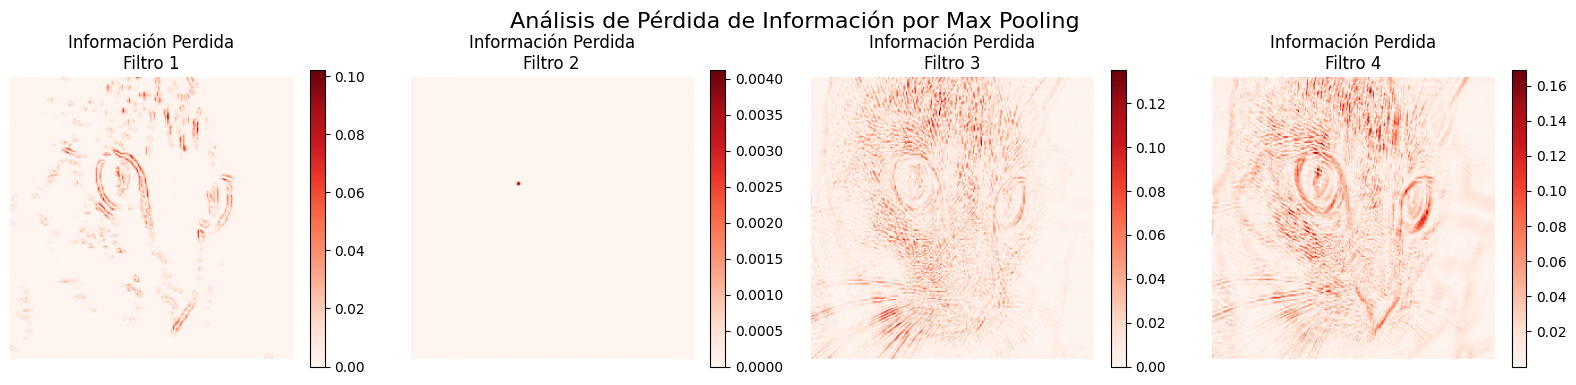


--- Histogramas de Distribución de Valores ---


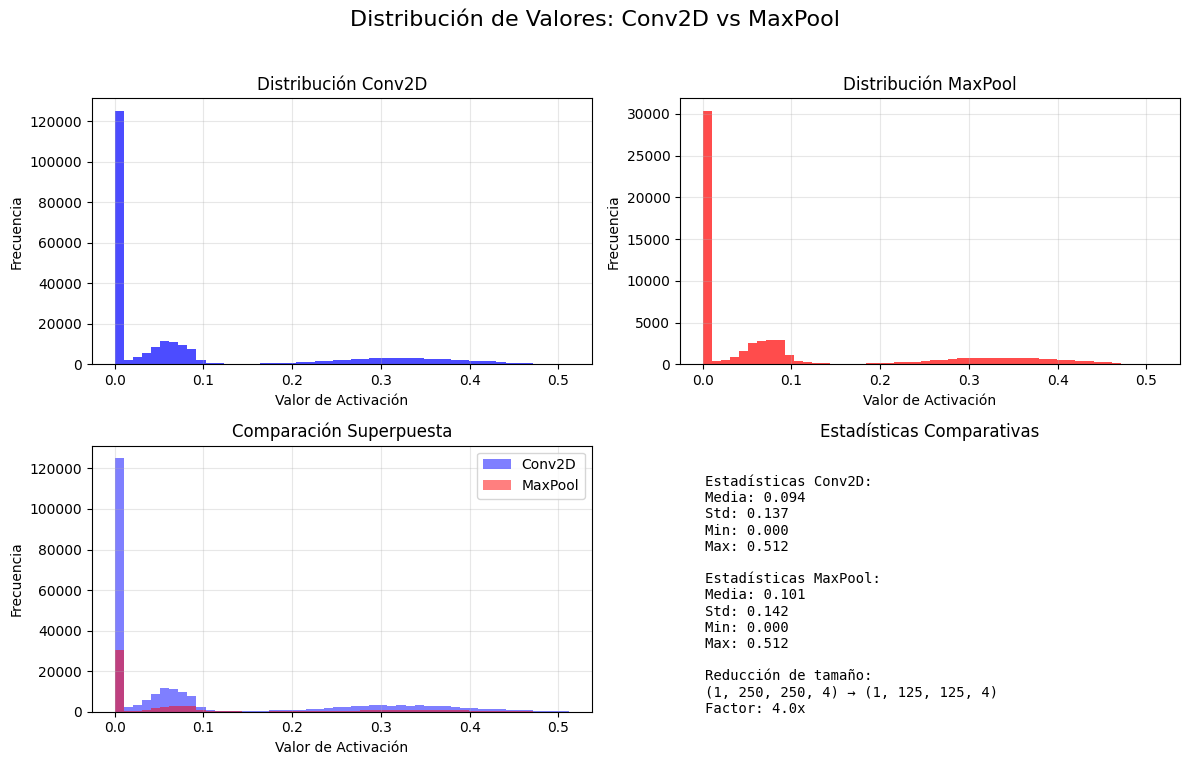


--- Análisis Completado ---
Reducción de activaciones (valores de salida): 250000 → 62500
Factor de reducción: 4.0x
Porcentaje de reducción: 75.0%


In [10]:
# Visualización 4: Diferencias entre capas
print("\n--- Visualización de Diferencias y Pérdida de Información ---")
fig, axes = plt.subplots(1, num_filtros, figsize=(16, 4))
fig.suptitle("Análisis de Pérdida de Información por Max Pooling", fontsize=16, y=0.95)

for i in range(num_filtros):
    # Redimensionar la salida del pooling para comparar
    pool_resized = tf.image.resize(
        salida_pool_activacion[0:1, :, :, i:i+1],
        [salida_conv_activacion.shape[1], salida_conv_activacion.shape[2]]
    ).numpy()

    # Calcular diferencia
    diferencia = np.abs(salida_conv_activacion[0, :, :, i] - pool_resized[0, :, :, 0])

    im = axes[i].imshow(diferencia, cmap='Reds')
    axes[i].set_title(f'Información Perdida\nFiltro {i+1}', fontsize=12)
    axes[i].axis('off')
    plt.colorbar(im, ax=axes[i])

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

# Visualización 5: Histogramas de distribución de valores
print("\n--- Histogramas de Distribución de Valores ---")
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle("Distribución de Valores: Conv2D vs MaxPool", fontsize=16, y=0.95)

# Histograma de todas las activaciones Conv2D
axes[0, 0].hist(salida_conv_activacion.flatten(), bins=50, alpha=0.7, color='blue')
axes[0, 0].set_title('Distribución Conv2D')
axes[0, 0].set_xlabel('Valor de Activación')
axes[0, 0].set_ylabel('Frecuencia')
axes[0, 0].grid(True, alpha=0.3)

# Histograma de todas las activaciones MaxPool
axes[0, 1].hist(salida_pool_activacion.flatten(), bins=50, alpha=0.7, color='red')
axes[0, 1].set_title('Distribución MaxPool')
axes[0, 1].set_xlabel('Valor de Activación')
axes[0, 1].set_ylabel('Frecuencia')
axes[0, 1].grid(True, alpha=0.3)

# Comparación superpuesta
axes[1, 0].hist(salida_conv_activacion.flatten(), bins=50, alpha=0.5, color='blue', label='Conv2D')
axes[1, 0].hist(salida_pool_activacion.flatten(), bins=50, alpha=0.5, color='red', label='MaxPool')
axes[1, 0].set_title('Comparación Superpuesta')
axes[1, 0].set_xlabel('Valor de Activación')
axes[1, 0].set_ylabel('Frecuencia')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Estadísticas resumidas
stats_text = f"""
Estadísticas Conv2D:
Media: {np.mean(salida_conv_activacion):.3f}
Std: {np.std(salida_conv_activacion):.3f}
Min: {np.min(salida_conv_activacion):.3f}
Max: {np.max(salida_conv_activacion):.3f}

Estadísticas MaxPool:
Media: {np.mean(salida_pool_activacion):.3f}
Std: {np.std(salida_pool_activacion):.3f}
Min: {np.min(salida_pool_activacion):.3f}
Max: {np.max(salida_pool_activacion):.3f}

Reducción de tamaño:
{salida_conv_activacion.shape} → {salida_pool_activacion.shape}
Factor: {(salida_conv_activacion.size / salida_pool_activacion.size):.1f}x
"""

axes[1, 1].text(0.05, 0.95, stats_text, transform=axes[1, 1].transAxes,
                fontsize=10, verticalalignment='top', fontfamily='monospace')
axes[1, 1].set_title('Estadísticas Comparativas')
axes[1, 1].axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

print("\n--- Análisis Completado ---")
print(f"Reducción de activaciones (valores de salida): {salida_conv_activacion.size} → {salida_pool_activacion.size}")
print(f"Factor de reducción: {salida_conv_activacion.size / salida_pool_activacion.size:.1f}x")
print(f"Porcentaje de reducción: {((salida_conv_activacion.size - salida_pool_activacion.size) / salida_conv_activacion.size) * 100:.1f}%")